In [18]:
library(plm)
library(lmtest)
library(lme4)
library(survival)
library(margins)
library(ggeffects)
library(magrittr)

In [2]:
df_path='../../data/dropbox/LaborDivision/Data/deriveddata/funding/funding_regression_data.csv'
data=read.csv(df_path)

In [3]:
head(data)

,X,id,year,dis,cluster_id,role,Code,gender,yfp,npub,F,L,M,ST,funded
,<int>,<int>,<int>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<chr>,<int>
1,0,43269102,2015,51,29411586,M,JPN,M,2000,74,3,0,5,Advanced,1
2,1,43269102,2015,51,492181,M,JPN,M,1983,287,0,11,43,Advanced,1
3,2,43269102,2015,51,492181,M,JPN,M,1983,287,0,11,43,Advanced,1
4,3,43269102,2015,51,7147306,M,JPN,M,1998,288,0,3,59,Advanced,1
5,4,43269102,2015,51,7147306,M,JPN,M,1998,288,0,3,59,Advanced,1
6,5,43269102,2015,51,7147306,M,JPN,M,1998,288,0,3,59,Advanced,1


In [4]:
data$npub=log(data$npub)

In [5]:
data$funded <- factor(data$funded, levels = c(0, 1), labels = c("NotFund", "Funded"))


In [6]:
data$fdep=ifelse(data$role == 'F', 1, 0)
data$ldep=ifelse(data$role == 'L', 1, 0)

In [7]:
unique_ids=unique(data$id)

In [8]:
sample_id=sample(unique_ids,5000)
sample_data=data[data$id %in% sample_id,]

### possiblity of being **first** author

In [9]:
fitclogit=clogit(fdep~gender+npub+ST+funded+strata(id),data = sample_data)

In [10]:
summary(fitclogit)

Call:
coxph(formula = Surv(rep(1, 41228L), fdep) ~ gender + npub + 
    ST + funded + strata(id), data = sample_data, method = "exact")

  n= 41228, number of events= 5355 

                 coef exp(coef) se(coef)      z Pr(>|z|)    
genderM      -0.23271   0.79238  0.03809  -6.11 9.95e-10 ***
npub         -0.16661   0.84653  0.01058 -15.74  < 2e-16 ***
STLagging     0.66938   1.95302  0.04332  15.45  < 2e-16 ***
fundedFunded  1.04906   2.85496  0.04203  24.96  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

             exp(coef) exp(-coef) lower .95 upper .95
genderM         0.7924     1.2620    0.7354    0.8538
npub            0.8465     1.1813    0.8291    0.8643
STLagging       1.9530     0.5120    1.7940    2.1261
fundedFunded    2.8550     0.3503    2.6292    3.1001

Concordance= 0.608  (se = 0.009 )
Likelihood ratio test= 1523  on 4 df,   p=<2e-16
Wald test            = 1141  on 4 df,   p=<2e-16
Score (logrank) test = 1327  on 4 df,   p=<2e-16


In [11]:
m1 = glmer(fdep~gender+npub+ST+funded+(1|id),data=sample_data,family = binomial)

In [12]:
summary(m1)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: binomial  ( logit )
Formula: fdep ~ gender + npub + ST + funded + (1 | id)
   Data: sample_data

     AIC      BIC   logLik deviance df.resid 
 30313.4  30365.1 -15150.7  30301.4    41222 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.9542 -0.4227 -0.3250 -0.2293 10.4883 

Random effects:
 Groups Name        Variance Std.Dev.
 id     (Intercept) 0.1954   0.4421  
Number of obs: 41228, groups:  id, 5000

Fixed effects:
              Estimate Std. Error z value Pr(>|z|)    
(Intercept)  -2.313125   0.051533 -44.886  < 2e-16 ***
genderM      -0.142092   0.033528  -4.238 2.26e-05 ***
npub         -0.115556   0.008565 -13.491  < 2e-16 ***
STLagging     0.498065   0.033170  15.015  < 2e-16 ***
fundedFunded  0.830380   0.037319  22.251  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
            (Intr) gendrM npu

### possiblity of being first author with interaction between funded and country group

In [14]:
m2 = glmer(fdep~gender+npub+ST+funded+ST*funded+(1|id),data=sample_data,family = binomial)

Warning message in checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv, :
“Model failed to converge with max|grad| = 0.00338142 (tol = 0.002, component 1)”


In [15]:
summary(m2)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: binomial  ( logit )
Formula: fdep ~ gender + npub + ST + funded + ST * funded + (1 | id)
   Data: sample_data

     AIC      BIC   logLik deviance df.resid 
 30268.0  30328.4 -15127.0  30254.0    41221 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.9353 -0.4257 -0.3408 -0.2096 11.7996 

Random effects:
 Groups Name        Variance Std.Dev.
 id     (Intercept) 0.192    0.4381  
Number of obs: 41228, groups:  id, 5000

Fixed effects:
                        Estimate Std. Error z value Pr(>|z|)    
(Intercept)            -2.519197   0.061666 -40.853  < 2e-16 ***
genderM                -0.132993   0.033539  -3.965 7.33e-05 ***
npub                   -0.118245   0.008586 -13.772  < 2e-16 ***
STLagging               0.888947   0.066264  13.415  < 2e-16 ***
fundedFunded            1.125162   0.058396  19.268  < 2e-16 ***
STLagging:fundedFunded -0.532406   0.077553  -6.865 6

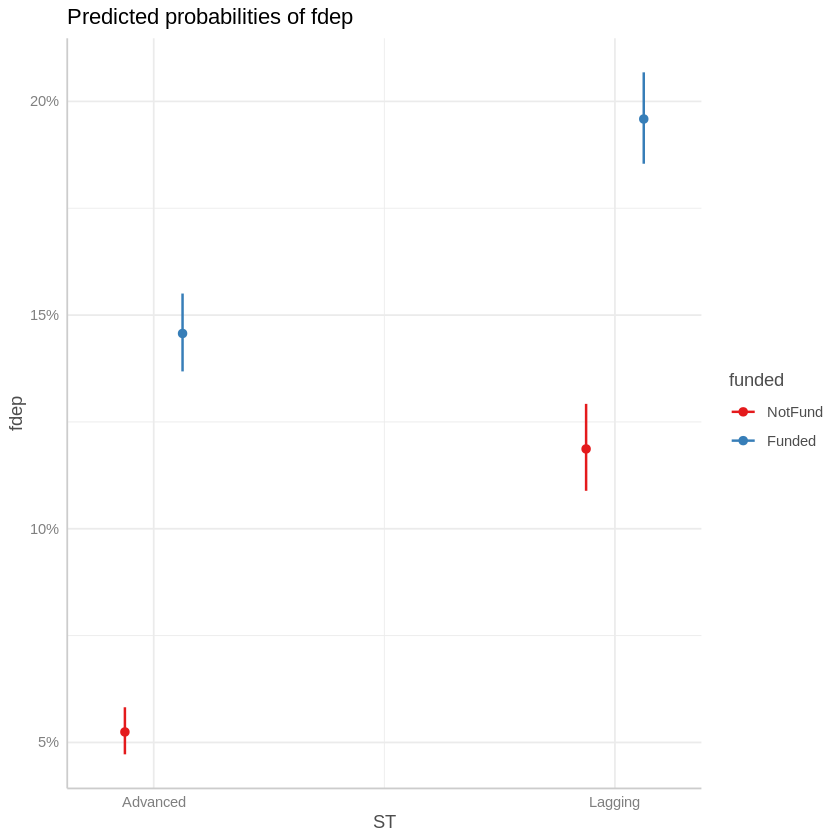

In [19]:
ggpredict(m2, c("ST", "funded")) %>% plot()

In [21]:
m3=glmer(ldep~gender+npub+ST+funded+(1|id),data=sample_data,family = binomial)

In [22]:
summary(m3)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: binomial  ( logit )
Formula: ldep ~ gender + npub + ST + funded + (1 | id)
   Data: sample_data

     AIC      BIC   logLik deviance df.resid 
 30463.8  30515.5 -15225.9  30451.8    41222 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.9920 -0.4171 -0.3097 -0.2039 12.5133 

Random effects:
 Groups Name        Variance Std.Dev.
 id     (Intercept) 0.4272   0.6536  
Number of obs: 41228, groups:  id, 5000

Fixed effects:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept)  -3.31542    0.05858 -56.599  < 2e-16 ***
genderM       0.29356    0.03855   7.615 2.63e-14 ***
npub          0.37180    0.01066  34.876  < 2e-16 ***
STLagging    -0.24146    0.03385  -7.134 9.75e-13 ***
fundedFunded  0.12744    0.03363   3.790 0.000151 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
            (Intr) gendrM npub   ST

In [24]:
m4=glmer(ldep~gender+npub+ST+funded+ST*funded+(1|id),data=sample_data,family = binomial)

In [25]:
summary(m4)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: binomial  ( logit )
Formula: ldep ~ gender + npub + ST + funded + ST * funded + (1 | id)
   Data: sample_data

     AIC      BIC   logLik deviance df.resid 
 30388.5  30448.9 -15187.3  30374.5    41221 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.0035 -0.4166 -0.3062 -0.2051 11.8515 

Random effects:
 Groups Name        Variance Std.Dev.
 id     (Intercept) 0.3965   0.6297  
Number of obs: 41228, groups:  id, 5000

Fixed effects:
                       Estimate Std. Error z value Pr(>|z|)    
(Intercept)            -3.17750    0.05975 -53.177  < 2e-16 ***
genderM                 0.28563    0.03847   7.424 1.13e-13 ***
npub                    0.37027    0.01058  34.997  < 2e-16 ***
STLagging              -0.65738    0.05949 -11.050  < 2e-16 ***
fundedFunded           -0.13186    0.04443  -2.968    0.003 ** 
STLagging:fundedFunded  0.66797    0.07632   8.753  < 2e-16

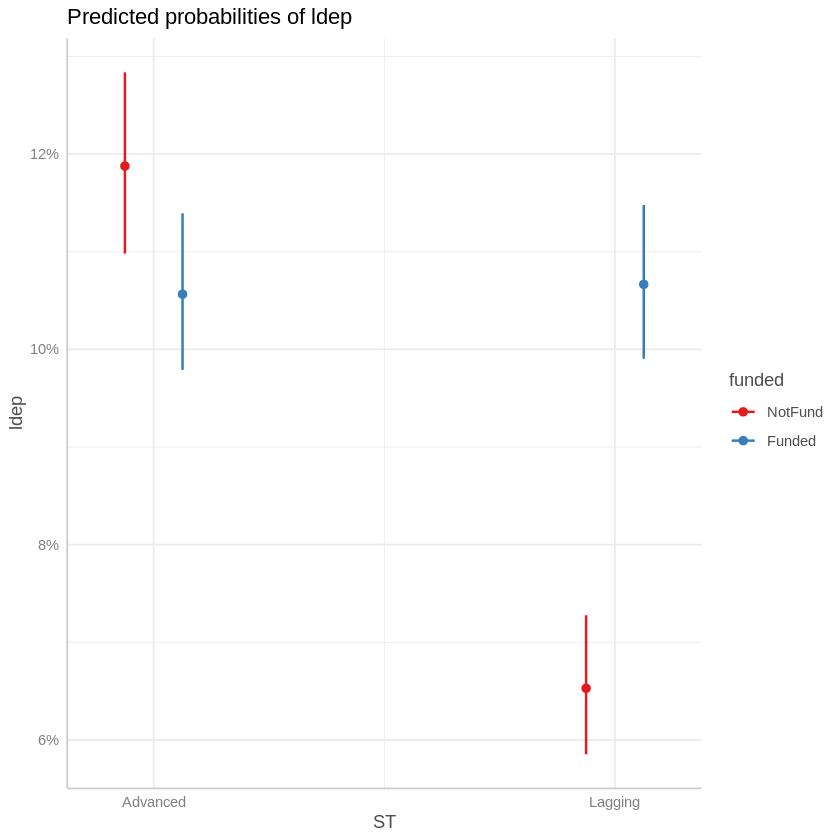

In [27]:
ggpredict(m4, c("ST", "funded")) %>% plot()